# MNIST-Fashion
https://github.com/zalandoresearch/fashion-mnist/tree/master

In [8]:
import numpy as np
from torchvision.datasets import FashionMNIST
train = FashionMNIST(root="data", train=True, download=True)
test = FashionMNIST(root="data", train=False, download=True)
#np.savez("fashion_mnist.npz",
#         x_train=train.data.numpy(), y_train=train.targets.numpy(),
#         x_test=test.data.numpy(), y_test=test.targets.numpy())


In [9]:
print(train.data.numpy().shape)
print(train.targets.numpy().shape)
print(test.data.numpy().shape)
print(test.targets.numpy().shape)

(60000, 28, 28)
(60000,)
(10000, 28, 28)
(10000,)


## Visualisering av dataene
(LLM-assisted: cellene under er skrevet med hjelp av Claude Code, 2026-11-18.)

1. Eksempelbilder per klasse
2. Klassebalanse i trenings- og testsettet
3. Gjennomsnittsbilde og standardavvik per klasse
4. Fordeling av pikselintensiteter
5. PCA-projeksjon (2D) – viser hvilke klasser som overlapper

In [10]:
# LLM-assisted (Claude Code, 2026-11-18): oppsett for visualisering
import matplotlib.pyplot as plt

x_train, y_train = train.data.numpy(), train.targets.numpy()
x_test, y_test = test.data.numpy(), test.targets.numpy()

class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
n_classes = len(class_names)
rng = np.random.default_rng(2026)

BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
GRAY = "#b4b2a9"

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "figure.dpi": 110})

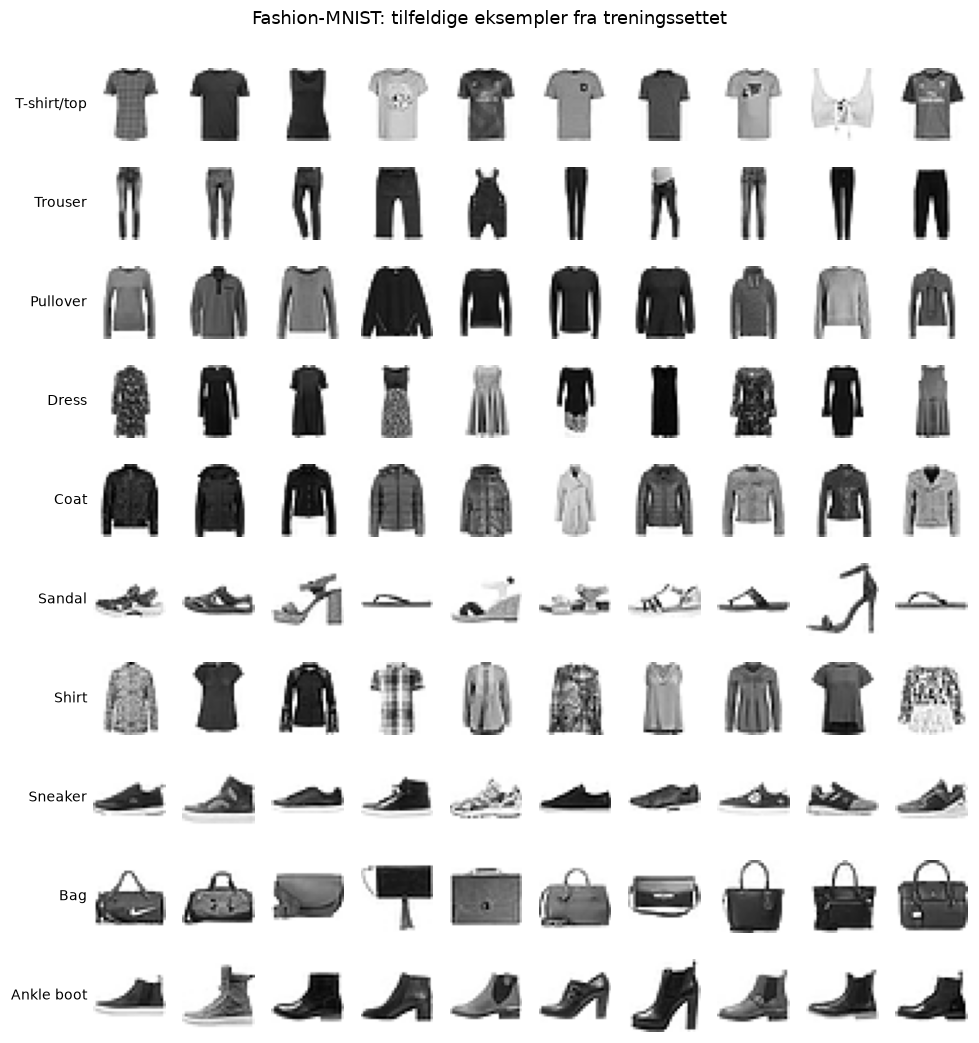

In [11]:
# LLM-assisted (Claude Code, 2026-11-18): rutenett med 10 tilfeldige eksempler per klasse
n_per_class = 10
fig, axes = plt.subplots(n_classes, n_per_class, figsize=(n_per_class * 0.9, n_classes * 0.95))
for c in range(n_classes):
    idx = rng.choice(np.flatnonzero(y_train == c), n_per_class, replace=False)
    for j, i in enumerate(idx):
        ax = axes[c, j]
        ax.imshow(x_train[i], cmap="gray_r", vmin=0, vmax=255)
        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values():
            s.set_visible(False)
    axes[c, 0].set_ylabel(class_names[c], rotation=0, ha="right", va="center", fontsize=9)
fig.suptitle("Fashion-MNIST: tilfeldige eksempler fra treningssettet", y=1.0)
plt.tight_layout()
plt.show()

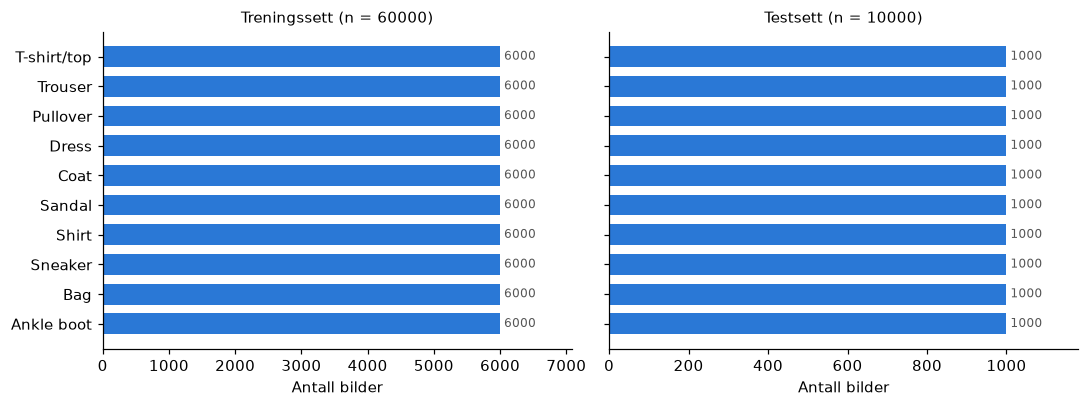

Andel per klasse (train): [0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1]
Andel per klasse (test):  [0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1]


In [12]:
# LLM-assisted (Claude Code, 2026-11-18): klassebalanse (to paneler, siden settene har ulik størrelse)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, y, name in zip(axes, [y_train, y_test], ["Treningssett", "Testsett"]):
    counts = np.bincount(y, minlength=n_classes)
    ax.barh(range(n_classes), counts, color=BLUE, height=0.7)
    for k, v in enumerate(counts):
        ax.text(v, k, f" {v}", va="center", fontsize=8, color="#555")
    ax.set_title(f"{name} (n = {len(y)})", fontsize=10)
    ax.set_xlabel("Antall bilder")
    ax.set_xlim(0, counts.max() * 1.18)
axes[0].set_yticks(range(n_classes), class_names)
axes[0].invert_yaxis()
plt.tight_layout()
plt.show()

print("Andel per klasse (train):", np.round(np.bincount(y_train) / len(y_train), 3))
print("Andel per klasse (test): ", np.round(np.bincount(y_test) / len(y_test), 3))

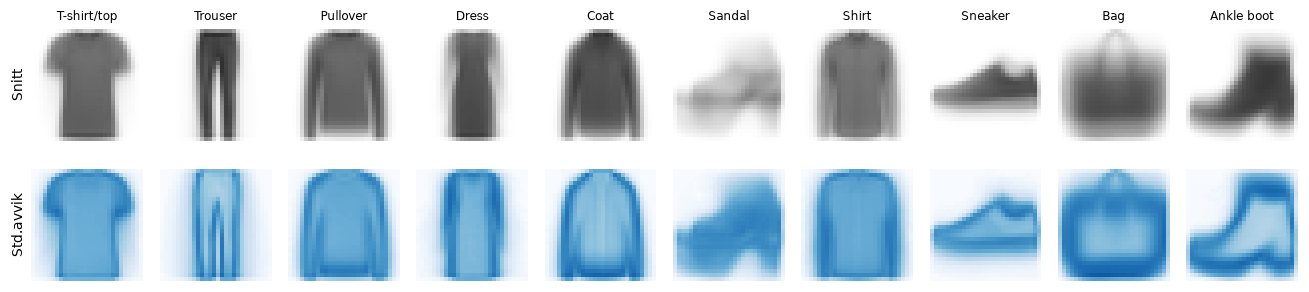

In [13]:
# LLM-assisted (Claude Code, 2026-11-18): gjennomsnittsbilde (øverst) og standardavvik (nederst) per klasse
X = x_train.astype(np.float32) / 255.0
fig, axes = plt.subplots(2, n_classes, figsize=(n_classes * 1.2, 3.0))
for c in range(n_classes):
    Xc = X[y_train == c]
    axes[0, c].imshow(Xc.mean(axis=0), cmap="gray_r", vmin=0, vmax=1)
    axes[1, c].imshow(Xc.std(axis=0), cmap="Blues", vmin=0, vmax=0.5)
    axes[0, c].set_title(class_names[c], fontsize=8)
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)
axes[0, 0].set_ylabel("Snitt", fontsize=9)
axes[1, 0].set_ylabel("Std.avvik", fontsize=9)
plt.tight_layout()
plt.show()

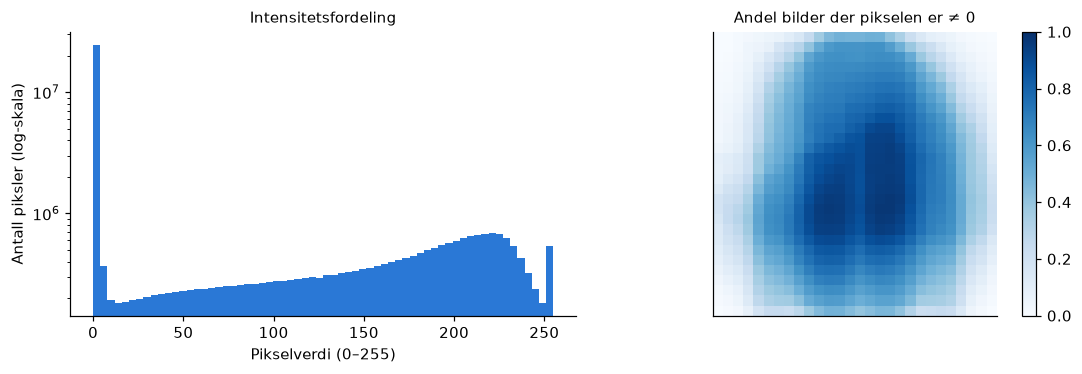

Andel piksler som er 0: 0.502
Piksler som er 0 i alle treningsbilder: 0 av 784


In [14]:
# LLM-assisted (Claude Code, 2026-11-18): fordeling av pikselintensiteter (alle treningsbilder)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(x_train.ravel(), bins=64, color=BLUE, log=True)
axes[0].set_xlabel("Pikselverdi (0–255)")
axes[0].set_ylabel("Antall piksler (log-skala)")
axes[0].set_title("Intensitetsfordeling", fontsize=10)

frac_nonzero = (x_train > 0).mean(axis=0)  # andel bilder der pikselen er > 0
im = axes[1].imshow(frac_nonzero, cmap="Blues", vmin=0, vmax=1)
axes[1].set_xticks([]); axes[1].set_yticks([])
axes[1].set_title("Andel bilder der pikselen er ≠ 0", fontsize=10)
fig.colorbar(im, ax=axes[1], fraction=0.046)
plt.tight_layout()
plt.show()

print(f"Andel piksler som er 0: {(x_train == 0).mean():.3f}")
print(f"Piksler som er 0 i alle treningsbilder: {(frac_nonzero == 0).sum()} av 784")

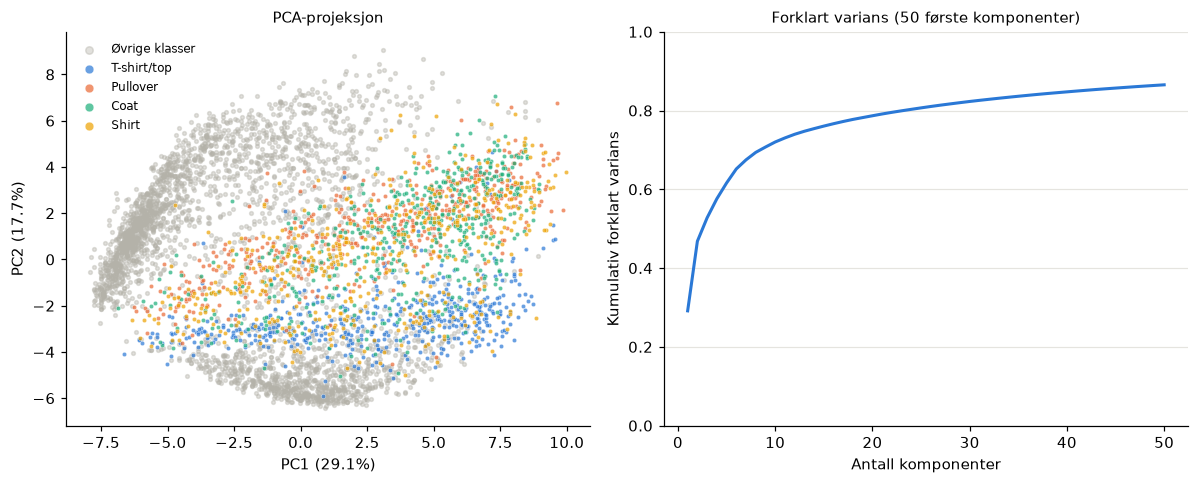

10 komponenter: 72.0%, 50 komponenter: 86.5% av variansen


In [15]:
# LLM-assisted (Claude Code, 2026-11-18): PCA-projeksjon til 2D av 5000 treningsbilder.
# Overkroppsplaggene (ofte forvekslet) er farget, de øvrige klassene er grå.
from sklearn.decomposition import PCA

sub = rng.choice(len(x_train), 5000, replace=False)
X_sub = x_train[sub].reshape(len(sub), -1) / 255.0
y_sub = y_train[sub]

pca = PCA(n_components=50, random_state=2026).fit(X_sub)
Z = pca.transform(X_sub)

highlight = {0: BLUE, 2: ORANGE, 4: AQUA, 6: YELLOW}  # T-shirt/top, Pullover, Coat, Shirt
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

ax = axes[0]
other = ~np.isin(y_sub, list(highlight))
ax.scatter(Z[other, 0], Z[other, 1], s=6, color=GRAY, alpha=0.4, label="Øvrige klasser")
for c, col in highlight.items():
    m = y_sub == c
    ax.scatter(Z[m, 0], Z[m, 1], s=8, color=col, alpha=0.7, edgecolors="white",
               linewidths=0.3, label=class_names[c])
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
ax.set_title("PCA-projeksjon", fontsize=10)
ax.legend(fontsize=8, markerscale=2, frameon=False)

ax = axes[1]
cum = np.cumsum(pca.explained_variance_ratio_)
ax.plot(np.arange(1, len(cum) + 1), cum, color=BLUE, lw=2)
ax.set_xlabel("Antall komponenter")
ax.set_ylabel("Kumulativ forklart varians")
ax.set_ylim(0, 1)
ax.grid(axis="y", color="#e5e4df", lw=0.8)
ax.set_title("Forklart varians (50 første komponenter)", fontsize=10)
plt.tight_layout()
plt.show()

print(f"10 komponenter: {cum[9]:.1%}, 50 komponenter: {cum[49]:.1%} av variansen")